# Text-to-Image and Image-to-image search Using CLIP

## Import libraries

#! pip install urllib3 -U
# !pip install --upgrade --force-reinstall datasets

In [1]:
import torch
import requests
import pandas as pd
from PIL import Image
from io import BytesIO
from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel, CLIPTokenizer

/home/bella/miniforge3/envs/consulting/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Image Exploration

### Load Data

In [2]:
# https://huggingface.co/datasets/conceptual_captions
image_data = load_dataset(
    "conceptual_captions", split="train",
    )

In [3]:
image_data

Dataset({
    features: ['image_url', 'caption'],
    num_rows: 3318333
})

We will select a sample of 300 images from this large number of images (3 318 333)

Let's examine how the dataset is structured

In [4]:
image_data_df = pd.DataFrame(image_data[:40])

In [5]:
image_data_df

,image_url,caption
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...
2,https://media.gettyimages.com/photos/young-con...,young confused girl standing in front of a war...
3,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...
4,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .
5,https://media.gettyimages.com/photos/jayz-atte...,gangsta rap artist attends sports team vs play...
6,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...
7,https://thumb1.shutterstock.com/display_pic_wi...,traditional ornamental floral paisley bandanna .
8,https://media.gettyimages.com/photos/bryan-mcc...,# of the sports team skates against sports tea...
9,http://www.robinhoodshow.com/clients/17668/864...,by geographical feature category or in the cit...


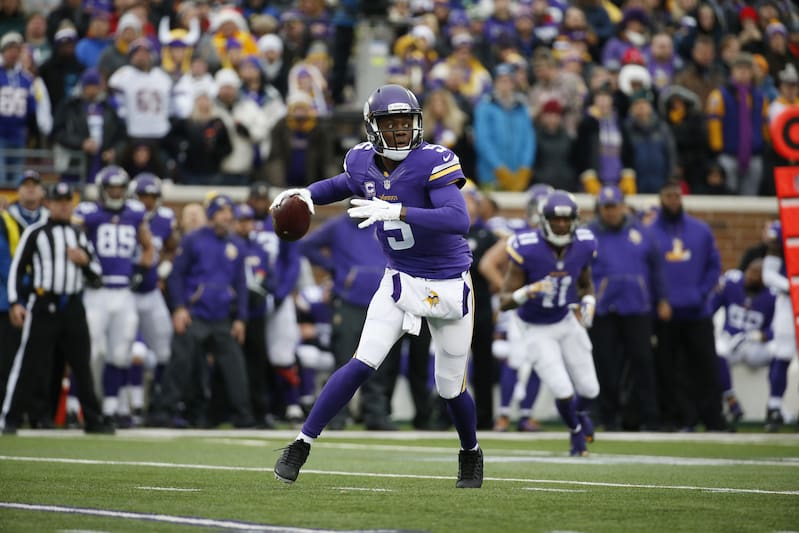

In [6]:
img_url = image_data_df.iloc[28]["image_url"]
image = Image.open(requests.get(img_url, stream=True).raw).convert('RGB')
image

In [7]:
image_data_df.iloc[28]["caption"]

'american football player looks downfield during the second half of a football game against sports team'

In [8]:
"""
Not all the URLs are valid. This function returns True if the URL is valid. False otherwise. 
"""
def check_valid_URLs(image_URL):

    try:
      response = requests.get(image_URL)
      Image.open(BytesIO(response.content))
      return True
    except:
      return False

def get_image(image_URL):

    response = requests.get(image_URL)
    image = Image.open(BytesIO(response.content)).convert("RGB")

    return image

def get_image_caption(image_ID):

    return image_data[image_ID]["caption"]

In [9]:
# Transform dataframe
image_data_df["is_valid"] = image_data_df["image_url"].apply(check_valid_URLs)

In [10]:
image_data_df = image_data_df[image_data_df["is_valid"]==True]
image_data_df.head()

,image_url,caption,is_valid
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station,True
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...,True
3,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...,True
4,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .,True
6,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...,True


In [11]:
image_data_df.shape

(23, 3)

In [12]:
image_data_df["image"] = image_data_df["image_url"].apply(get_image)

/home/bella/miniforge3/envs/consulting/lib/python3.13/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


all shots by by person and rider shots can be found on his website .


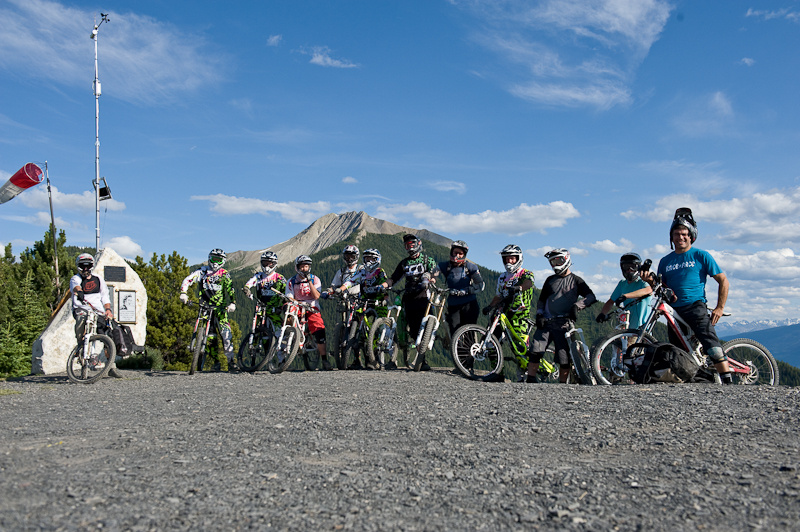

In [13]:
print(image_data_df.iloc[9]["caption"])
image_data_df.iloc[9]["image"]

## Load the model

In [14]:
def get_model_info(model_ID, device):

  # Save the model to device
  model = CLIPModel.from_pretrained(model_ID).to(device)

  # Get the processor
  processor = CLIPProcessor.from_pretrained(model_ID)

  # Get the tokenizer
  tokenizer = CLIPTokenizer.from_pretrained(model_ID)

  # Return model, processor & tokenizer
  return model, processor, tokenizer

In [15]:
# Set the device
device = "cuda" if torch.cuda.is_available() else "cpu"

model_ID = "openai/clip-vit-base-patch32"

model, processor, tokenizer = get_model_info(model_ID, device)

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


## Create Embeddings: Text and Image Embeddings

### Text Embeddings

In [16]:
def get_single_text_embedding(text):

  inputs = tokenizer(text, return_tensors = "pt").to(device)

  text_embeddings = model.get_text_features(**inputs)

  # convert the embeddings to numpy array 
  embedding_as_np = text_embeddings.cpu().detach().numpy()

  return embedding_as_np

In [17]:
def get_all_text_embeddings(df, text_col):

   df["text_embeddings"] = df[str(text_col)].apply(get_single_text_embedding)

   return df 

In [18]:
image_data_df = get_all_text_embeddings(image_data_df, "caption")

In [19]:
image_data_df.head()

,image_url,caption,is_valid,image,text_embeddings
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station,True,<PIL.Image.Image image mode=RGB size=800x534 a...,"[[0.25922292, -0.08825895, 0.020317025, -0.127..."
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...,True,<PIL.Image.Image image mode=RGB size=500x441 a...,"[[0.0041466653, 0.1894356, -0.12397026, 0.3029..."
3,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.56064546, -0.15138066, -0.43740314, -0.339..."
4,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.035292834, 0.242628, -0.12724736, -0.21021..."
6,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...,True,<PIL.Image.Image image mode=RGB size=1200x678 ...,"[[0.18494767, 0.37737116, 0.23176077, -0.14631..."


### Image Embeddings

In [20]:
def get_single_image_embedding(my_image):

  image = processor(
      text = None,
      images = my_image, 
      return_tensors="pt"
  )["pixel_values"].to(device)

  embedding = model.get_image_features(image)

  # convert the embeddings to numpy array
  embedding_as_np = embedding.cpu().detach().numpy()

  return embedding_as_np

### Get the embedding of all the images

In [21]:
def get_all_images_embedding(df, img_column):

  df["img_embeddings"] = df[str(img_column)].apply(get_single_image_embedding)

  return df

In [22]:
image_data_df = get_all_images_embedding(image_data_df, "image")

In [23]:
image_data_df.head()

,image_url,caption,is_valid,image,text_embeddings,img_embeddings
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station,True,<PIL.Image.Image image mode=RGB size=800x534 a...,"[[0.25922292, -0.08825895, 0.020317025, -0.127...","[[-0.0034019798, -0.05358342, 0.3524745, 0.331..."
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...,True,<PIL.Image.Image image mode=RGB size=500x441 a...,"[[0.0041466653, 0.1894356, -0.12397026, 0.3029...","[[-0.25020266, -0.13257791, 0.09706275, 0.9788..."
3,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.56064546, -0.15138066, -0.43740314, -0.339...","[[-0.16011266, -0.29582846, -0.11380373, -0.04..."
4,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.035292834, 0.242628, -0.12724736, -0.21021...","[[0.18214451, 0.050187513, -0.64188576, -0.079..."
6,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...,True,<PIL.Image.Image image mode=RGB size=1200x678 ...,"[[0.18494767, 0.37737116, 0.23176077, -0.14631...","[[0.054596007, -0.13548386, -0.0031616539, -0...."


### Helper function to plot images

In [24]:
import matplotlib.pyplot as plt

def plot_images(images):

  for image in images:
    plt.imshow(image)
    plt.show()

def plot_images_by_side(top_images):

  index_values = list(top_images.index.values)
  list_images = [top_images.iloc[idx].image for idx in index_values] 
  list_captions = [top_images.iloc[idx].caption for idx in index_values] 
  similarity_score = [top_images.iloc[idx].cos_sim for idx in index_values] 

  n_row = n_col = 2

  _, axs = plt.subplots(n_row, n_col, figsize=(12, 12))
  axs = axs.flatten()
  for img, ax, caption, sim_score in zip(list_images, axs, list_captions, similarity_score):
      ax.imshow(img)
      sim_score = 100*float("{:.2f}".format(sim_score))
      ax.title.set_text(f"Caption: {caption}\nSimilarity: {sim_score}%")
  plt.show()

## Perform Similarity Search: Cosine 

### 1. Cosine Similarity Search

In [25]:
from sklearn.metrics.pairwise import cosine_similarity

In [26]:
def get_top_N_images(query, data, top_K=4, search_criterion="text"):

    """
    Retrieve top_K (5 is default value) articles similar to the query
    """
    # Text to image Search
    if search_criterion.lower() == "text":
      query_vect = get_single_text_embedding(query)

    # Image to image Search
    else: 
      query_vect = get_single_image_embedding(query)

    # Relevant columns
    revevant_cols = ["caption", "image", "cos_sim"]
    
    # Run similarity Search
    data["cos_sim"] = data["img_embeddings"].apply(lambda x: cosine_similarity(query_vect, x))

    data["cos_sim"] = data["cos_sim"].apply(lambda x: x[0][0])
    
    """
    Sort Cosine Similarity Column in Descending Order 
    Here we start at 1 to remove similarity with itself because it is always 1
    """
    most_similar_articles = data.sort_values(by='cos_sim', ascending=False)[0:top_K+1]
    
    return most_similar_articles[revevant_cols].reset_index()

In [27]:
image_data_df.columns

Index(['image_url', 'caption', 'is_valid', 'image', 'text_embeddings',
       'img_embeddings'],
      dtype='str')

#### a. Text to image search

In [28]:
image_data_df.iloc[10].caption

'photo of a deer and wildfire'

In [29]:
query_caption = 'american football player looks downfield during the second half of a football game against sports team'

top_images = get_top_N_images(query_caption, image_data_df)
print("Query: {}".format(query_caption))
top_images

Query: american football player looks downfield during the second half of a football game against sports team


,index,caption,image,cos_sim
0,28,american football player looks downfield durin...,<PIL.Image.Image image mode=RGB size=799x533 a...,0.262951
1,4,cybernetic scene isolated on white background .,<PIL.Image.Image image mode=RGB size=450x470 a...,0.197659
2,20,photo of a deer and wildfire,<PIL.Image.Image image mode=RGB size=200x200 a...,0.181171
3,37,racecar driver steers his car during video gam...,<PIL.Image.Image image mode=RGB size=1024x577 ...,0.166300
4,8,# of the sports team skates against sports tea...,<PIL.Image.Image image mode=RGB size=491x612 a...,0.165662


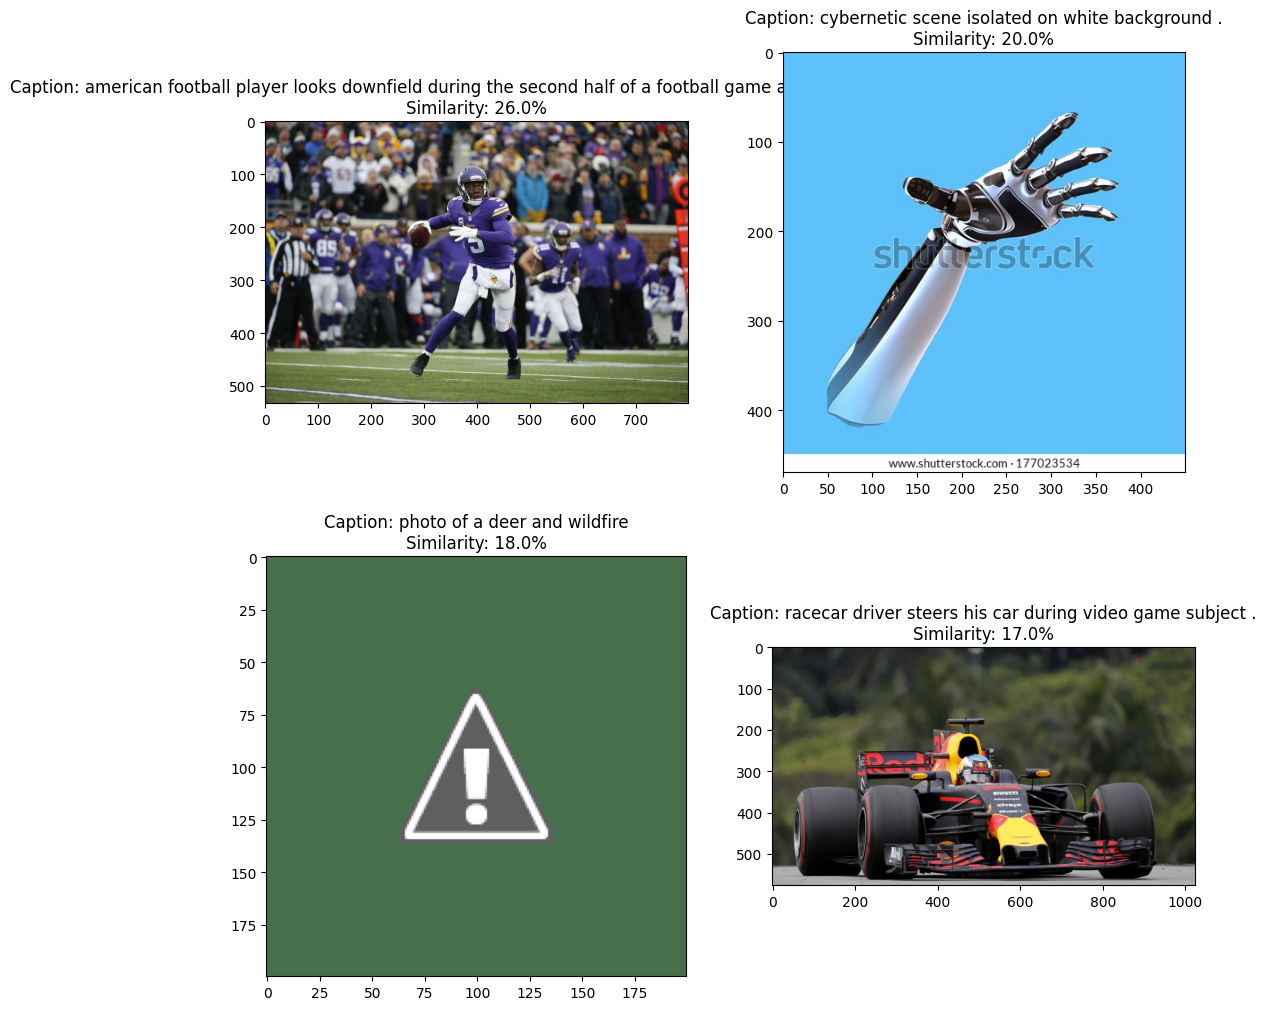

In [30]:
plot_images_by_side(top_images)

#### b. Image to image search

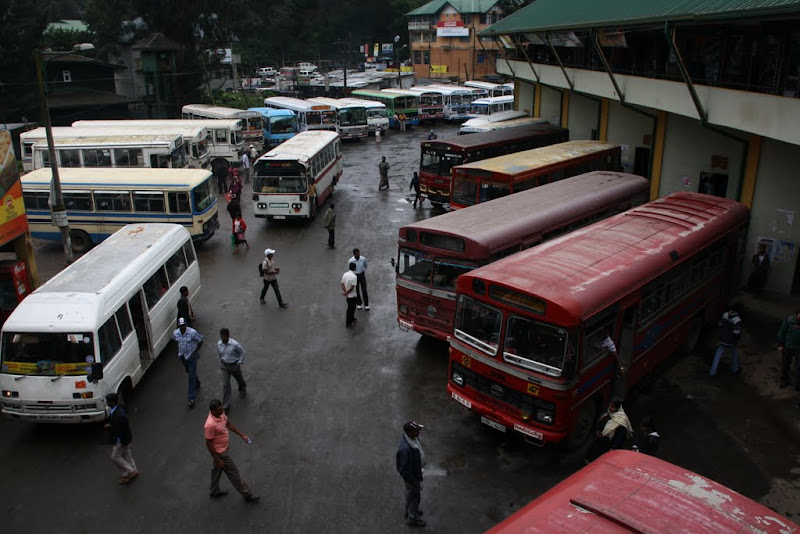

In [31]:
query_image = image_data_df.iloc[0].image
query_image

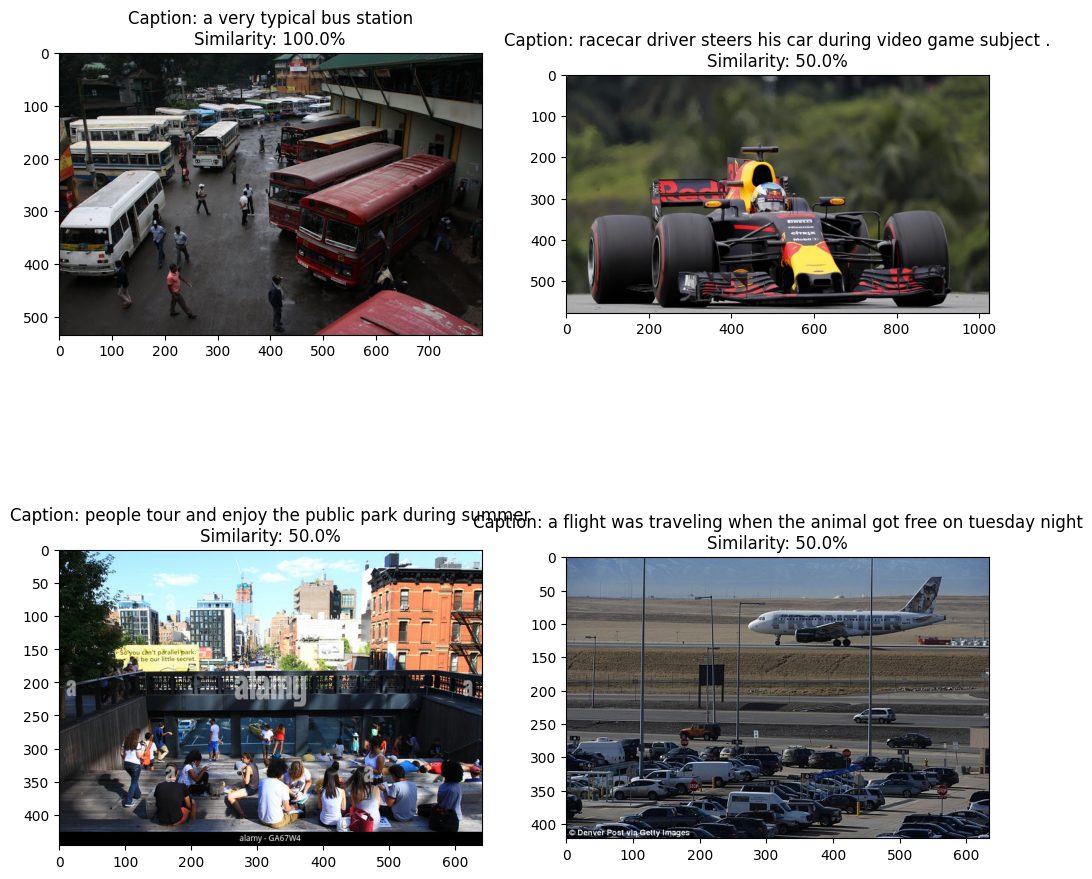

In [32]:
top_images = get_top_N_images(query_image, image_data_df, search_criterion="image")
plot_images_by_side(top_images)

# Approach n°2: Pinecone Client Library

#### Initializing the Index

Now we need a place to store these embeddings and enable a efficient vector search through them all. To do that we use Pinecone, we can get a [free API key](https://app.pinecone.io/) and enter it below where we will initialize our connection to Pinecone and create a new index.

!pip install -qU langchain-pinecone pinecone-notebooks

In [34]:
import os
from pinecone import Pinecone
from dotenv import load_dotenv, find_dotenv

_ = load_dotenv(find_dotenv())
api_key = os.environ.get('PINECONE_API_KEY') or 'PINECONE_API_KEY'

# configure client
pc = Pinecone(api_key=api_key)

Now we setup our index specification, this allows us to define the cloud provider and region where we want to deploy our index. You can find a list of all [available providers and regions here](https://docs.pinecone.io/docs/projects).

In [35]:
from pinecone import ServerlessSpec

cloud = os.environ.get('PINECONE_CLOUD') or 'aws'
region = os.environ.get('PINECONE_REGION') or 'us-east-1'

spec = ServerlessSpec(cloud=cloud, region=region)

Create the index:

In [36]:
my_index_name = "clip-image-search"

In [37]:
import time

vector_dim = image_data_df.img_embeddings[0].shape[1]

# check if index already exists (it shouldn't if this is first time)
if my_index_name not in pc.list_indexes().names():
    # if does not exist, create index
    pc.create_index(
        my_index_name,
        dimension=vector_dim,
        metric='cosine',
        spec=spec
    )
    # wait for index to be initialized
    while not pc.describe_index(my_index_name).status['ready']:
        time.sleep(1)

# connect to index
my_index = pc.Index(my_index_name)
# view index stats
my_index.describe_index_stats()

{'dimension': 512,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {},
 'total_vector_count': 0,
 'vector_type': 'dense'}

#### Prepare Vector

In [38]:
image_data_df

,image_url,caption,is_valid,image,text_embeddings,img_embeddings,cos_sim
0,http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/...,a very typical bus station,True,<PIL.Image.Image image mode=RGB size=800x534 a...,"[[0.25922292, -0.08825895, 0.020317025, -0.127...","[[-0.0034019798, -0.05358342, 0.3524745, 0.331...",1.000000
1,http://78.media.tumblr.com/3b133294bdc7c7784b7...,sierra looked stunning in this top and this sk...,True,<PIL.Image.Image image mode=RGB size=500x441 a...,"[[0.0041466653, 0.1894356, -0.12397026, 0.3029...","[[-0.25020266, -0.13257791, 0.09706275, 0.9788...",0.164990
3,https://thumb1.shutterstock.com/display_pic_wi...,interior design of modern living room with fir...,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.56064546, -0.15138066, -0.43740314, -0.339...","[[-0.16011266, -0.29582846, -0.11380373, -0.04...",0.315705
4,https://thumb1.shutterstock.com/display_pic_wi...,cybernetic scene isolated on white background .,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[0.035292834, 0.242628, -0.12724736, -0.21021...","[[0.18214451, 0.050187513, -0.64188576, -0.079...",0.350875
6,https://prismpub.com/wp-content/uploads/2016/1...,the jetty : different types of plants to estab...,True,<PIL.Image.Image image mode=RGB size=1200x678 ...,"[[0.18494767, 0.37737116, 0.23176077, -0.14631...","[[0.054596007, -0.13548386, -0.0031616539, -0....",0.391565
7,https://thumb1.shutterstock.com/display_pic_wi...,traditional ornamental floral paisley bandanna .,True,<PIL.Image.Image image mode=RGB size=450x470 a...,"[[-0.05619796, -0.34935424, 0.4283249, -0.1160...","[[0.28839582, -0.106545776, 0.07449685, -0.236...",0.358286
8,https://media.gettyimages.com/photos/bryan-mcc...,# of the sports team skates against sports tea...,True,<PIL.Image.Image image mode=RGB size=491x612 a...,"[[-0.09968633, -0.18738121, -0.26996517, -0.17...","[[-0.38872194, -0.0781933, -0.18983577, 0.0042...",0.318213
10,http://i.dailymail.co.uk/i/pix/2016/08/10/15/3...,a flight was traveling when the animal got fre...,True,<PIL.Image.Image image mode=RGB size=634x422 a...,"[[0.35373235, -0.16590074, -0.19086389, -0.138...","[[0.09851645, 0.27600178, 0.19929013, 0.357076...",0.496374
14,http://images.gmanews.tv/webpics/2016/11/640_2...,celebrities start decorating for the christmas...,True,<PIL.Image.Image image mode=RGB size=640x640 a...,"[[0.25235158, -0.12619601, 0.16562524, 0.34066...","[[0.45487702, 0.022064477, -0.12971123, 0.2394...",0.397812
19,https://ep1.pinkbike.org/p4pb6973204/p4pb69732...,all shots by by person and rider shots can be ...,True,<PIL.Image.Image image mode=RGB size=800x532 a...,"[[0.042263806, 0.36848265, 0.063882574, -0.202...","[[-0.32782176, 0.40221876, 0.042629555, 0.1975...",0.434753


In [39]:
image_data_df["vector_id"] = image_data_df.index
image_data_df["vector_id"] = image_data_df["vector_id"].apply(str)

# Get all the metadata
final_metadata = []

for index in range(len(image_data_df)):
  final_metadata.append({
      'ID':  index,
      'caption': image_data_df.iloc[index].caption, 
      'image': image_data_df.iloc[index].image_url
  })

image_IDs = image_data_df.vector_id.tolist()
image_embeddings = [arr.flatten().tolist() for arr in image_data_df.img_embeddings.tolist()] 

# Create the single list of dictionary format to insert 
data_to_upsert = list(zip(image_IDs, image_embeddings, final_metadata))

# Upload the final data
my_index.upsert(vectors = data_to_upsert)

# Check index size for each namespace
my_index.describe_index_stats()

{'dimension': 512,
 'index_fullness': 0.0,
 'metric': 'cosine',
 'namespaces': {'': {'vector_count': 23}},
 'total_vector_count': 23,
 'vector_type': 'dense'}

In [40]:
data_to_upsert

[('0',
  [-0.0034019798040390015,
   -0.05358342081308365,
   0.35247451066970825,
   0.3310978412628174,
   -0.12070023268461227,
   -0.12660327553749084,
   0.5595039129257202,
   0.06007477641105652,
   -0.02865441143512726,
   0.3338189125061035,
   0.18622377514839172,
   0.09372603893280029,
   0.1618884950876236,
   -0.1823374181985855,
   0.1875709593296051,
   -0.030621100217103958,
   -0.5870618224143982,
   0.18503785133361816,
   -0.19818300008773804,
   -0.4541376233100891,
   -0.06845413148403168,
   0.33585160970687866,
   -0.08771556615829468,
   -0.40584608912467957,
   -0.1357433944940567,
   0.07969728857278824,
   0.3663281202316284,
   -0.4162825345993042,
   -0.07663416862487793,
   -0.34289368987083435,
   -0.28519123792648315,
   -0.3111496567726135,
   -0.24940277636051178,
   -0.4748559594154358,
   0.34044498205184937,
   0.14211340248584747,
   -0.40818727016448975,
   0.6022752523422241,
   0.17238786816596985,
   0.8532313704490662,
   -0.18382132053375244

### Text to image

In [41]:
text_query = image_data_df.iloc[10].caption
text_query

'photo of a deer and wildfire'

In [42]:
# Get the caption embedding
query_embedding = get_single_text_embedding(text_query).tolist()

In [43]:
# Run the query
my_index.query(vector=query_embedding, top_k=4, include_metadata=True)

{'matches': [{'id': '3',
              'metadata': {'ID': 2.0,
                           'caption': 'interior design of modern living room '
                                      'with fireplace in a new house',
                           'image': 'https://thumb1.shutterstock.com/display_pic_with_logo/152074/125938838/stock-photo-interior-design-of-modern-living-room-with-fireplace-in-a-new-house-125938838.jpg'},
              'score': 0.224858657,
              'values': []},
             {'id': '20',
              'metadata': {'ID': 10.0,
                           'caption': 'photo of a deer and wildfire',
                           'image': 'http://2.bp.blogspot.com/-cZpqM2kr2uc/U6v-pnIxM9I/AAAAAAAAaek/OFq7OBbqkv4/s1600/photo-of-a-deer-with-a-wildfire-in-the-background-hd-deer-wallpapers.jpg'},
              'score': 0.200125933,
              'values': []},
             {'id': '39',
              'metadata': {'ID': 22.0,
                           'caption': 'heavy snow falls ove

### Image to image

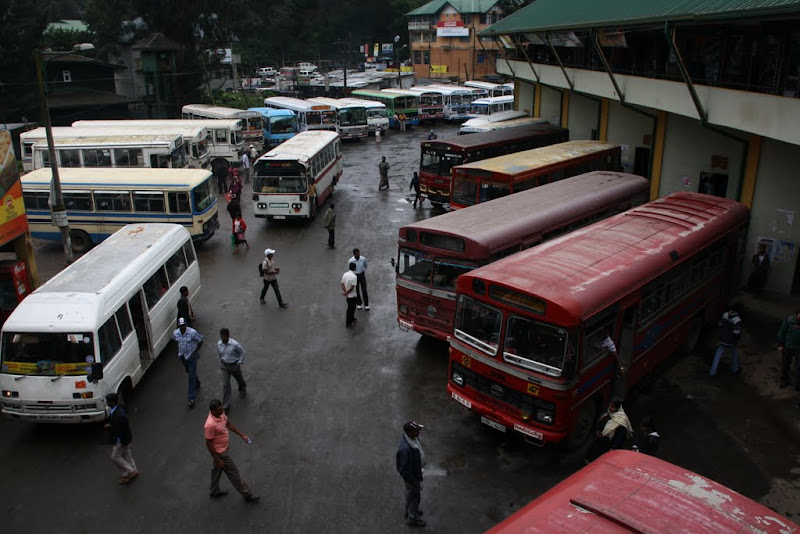

In [44]:
image_query = image_data_df.iloc[0].image
image_query

In [45]:
# Get the text embedding
query_embedding = get_single_image_embedding(image_query).tolist()

In [46]:
# Run the query
my_index.query(vector=query_embedding, top_k=4, include_metadata=True)

{'matches': [{'id': '0',
              'metadata': {'ID': 0.0,
                           'caption': 'a very typical bus station',
                           'image': 'http://lh6.ggpht.com/-IvRtNLNcG8o/TpFyrudaT6I/AAAAAAAAM6o/_11MuAAKalQ/IMG_3422.JPG?imgmax=800'},
              'score': 1.00371885,
              'values': []},
             {'id': '37',
              'metadata': {'ID': 20.0,
                           'caption': 'racecar driver steers his car during '
                                      'video game subject .',
                           'image': 'http://cdn.newsapi.com.au/image/v1/af347cd6569987c49a71fe05870753c5?width=1024'},
              'score': 0.506423414,
              'values': []},
             {'id': '35',
              'metadata': {'ID': 18.0,
                           'caption': 'people tour and enjoy the public park '
                                      'during summer',
                           'image': 'http://l7.alamy.com/zooms/a4197bf168734006b10e

#### Delete your index

Once finished with the index we can delete it to save resources.

In [47]:
pc.delete_index(my_index_name)

# LangGraph vs create_agent: Building an Image Search Agent

## Understanding the Transition from `AgentExecutor` to LangGraph

In LangChain 0.x, agents were created using `create_react_agent` + `AgentExecutor`. In LangChain 1.0+, **LangGraph** provides a more flexible, graph-based approach to building agents with explicit state management.

Below we compare both approaches side-by-side, using our CLIP image search as the underlying tool.

## Step 3 (New Approach): LangGraph `create_react_agent` (LangChain 1.0+)

LangGraph simplifies agent creation significantly:
1. **No prompt template needed** - LangGraph uses a built-in ReAct loop
2. **No AgentExecutor** - `create_react_agent` from LangGraph returns a runnable graph directly
3. **Memory via checkpointer** - Instead of `ConversationBufferWindowMemory`, use `MemorySaver` with thread IDs
4. **Message-based interface** - Input/output uses a messages list instead of `{"input": "..."}`

### Key Differences:
| Aspect | Old (AgentExecutor) | New (LangGraph) |
|--------|-------------------|-----------------|
| Agent creation | `create_react_agent()` + `AgentExecutor()` | `create_react_agent()` (single call) |
| Memory | `ConversationBufferWindowMemory` | `MemorySaver` checkpointer |
| Input format | `{"input": "query"}` | `{"messages": [("user", "query")]}` |
| Output format | `result["output"]` | `result["messages"][-1].content` |
| Prompt | Must pull from Hub | Built-in ReAct prompt |
| Error handling | `handle_parsing_errors=True` | Built into the graph |

In [50]:
# --- NEW APPROACH (LangGraph / LangChain 1.0+) ---

from langgraph.prebuilt import create_react_agent
from langgraph.checkpoint.memory import MemorySaver
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-3.5-turbo", temperature=0)

# Create a checkpointer for conversation memory
memory = MemorySaver()

# Create the agent - much simpler than the old approach!
# No prompt template needed, no AgentExecutor wrapper
langgraph_agent = create_react_agent(
    model=llm,
    tools=[clip_search_tool],
    checkpointer=memory,
)

# Run the LangGraph agent
config = {"configurable": {"thread_id": "clip-search-1"}}

result = langgraph_agent.invoke(
    {"messages": [("user", "Find me images of animals in nature")]},
    config=config
)
print("LangGraph Agent Result:", result["messages"][-1].content)

/tmp/ipykernel_44999/2270552537.py:14: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  langgraph_agent = create_react_agent(


LangGraph Agent Result: Here are some images related to animals in nature:

1. Caption: Portrait of a smiling woman stroking her dog lying on a couch (Similarity: 22.11%)
2. Caption: Heavy snow falls over a snow-lined river (Similarity: 21.88%)
3. Caption: Funny animals of the week, animal pictures (Similarity: 21.63%)
4. Caption: Cybernetic scene isolated on a white background (Similarity: 21.39%)

If you would like to see more images or have specific preferences, feel free to let me know!


## Step 4: Conversation Memory with LangGraph

With LangGraph, conversation memory is handled through the checkpointer. Each `thread_id` maintains its own conversation history. Let's demonstrate a follow-up question.

In [51]:
# Follow-up question using the same thread_id (memory is preserved)
result2 = langgraph_agent.invoke(
    {"messages": [("user", "What about sports-related images?")]},
    config=config  # Same thread_id, so it remembers the previous query
)
print("Follow-up Result:", result2["messages"][-1].content)

# To start a fresh conversation, simply use a new thread_id:
new_config = {"configurable": {"thread_id": "clip-search-2"}}
result3 = langgraph_agent.invoke(
    {"messages": [("user", "Show me images of architecture")]},
    config=new_config
)
print("\nNew Thread Result:", result3["messages"][-1].content)

Follow-up Result: Here are some images related to sports:

1. Caption: Cybernetic scene isolated on a white background (Similarity: 24.83%)
2. Caption: American football player looks downfield during the second half of a football game against a sports team (Similarity: 21.72%)
3. Caption: Photo of a deer and wildfire (Similarity: 21.70%)
4. Caption: # of the sports team skates against sports team during their game (Similarity: 21.45%)

If you would like to see more sports-related images or have specific sports in mind, feel free to let me know!

New Thread Result: Here are some images related to architecture:
1. Image of the interior design of a modern living room with a fireplace in a new house (Similarity: 23.93%)
2. Image of a traditional ornamental floral paisley bandanna (Similarity: 22.65%)
3. Image of a young business woman on a bench (Similarity: 21.96%)
4. Image of a sign against a blue sky (Similarity: 21.89%)


# VLM (Vision Language Model) vs LLM + CLIP

## Understanding the Difference

### LLM + CLIP (used above)
- **CLIP** handles the visual understanding (embedding images into a shared text-image space)
- **LLM** (e.g., GPT-3.5) handles reasoning, conversation, and tool orchestration
- The LLM **never sees the images directly** - it only works with text (captions, similarity scores)
- This is a **two-model pipeline**: CLIP for vision + LLM for language

### VLM (Vision Language Model)
- A **single model** (e.g., GPT-4o, GPT-4 Vision) that can process **both text and images natively**
- The model **directly sees and understands images** - no need for separate embeddings
- Can describe, analyze, compare, and reason about images in a single step
- More powerful for complex visual reasoning, but more expensive per query

### When to use which?
| Use Case | LLM + CLIP | VLM |
|----------|-----------|-----|
| Image search/retrieval | Best choice - fast, scalable embeddings | Overkill for search |
| Image description/analysis | Limited to pre-computed captions | Excellent - direct understanding |
| Visual question answering | Cannot answer visual questions | Native capability |
| Cost per query | Lower (CLIP is local, LLM is cheap) | Higher (VLM inference is expensive) |
| Batch processing | Fast parallel embeddings | Slower, sequential |

## Example: LLM + CLIP Approach (what we did above)

The LLM orchestrates the search but relies on CLIP for visual understanding.

In [52]:
# LLM + CLIP approach: The LLM uses CLIP as a tool
# The LLM never "sees" images - it only gets text results from CLIP
# Pros: Fast search, scalable, lower cost
# Cons: LLM cannot reason about image content directly

llm_only = ChatOpenAI(model="gpt-3.5-turbo", temperature=0)  # Text-only LLM

# The LLM uses our CLIP tool to search - it gets back text descriptions
llm_clip_agent = create_react_agent(
    model=llm_only,
    tools=[clip_search_tool],
)

result_llm_clip = llm_clip_agent.invoke(
    {"messages": [("user", "Find images that show outdoor scenes with people")]}
)
print("LLM + CLIP Result:")
print(result_llm_clip["messages"][-1].content)

/tmp/ipykernel_44999/859468124.py:9: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  llm_clip_agent = create_react_agent(


LLM + CLIP Result:
I found some images that show outdoor scenes with people. Here are the captions and their similarity scores:

1. Caption: Young business woman on a bench (Similarity: 26.54%)
2. Caption: People tour and enjoy the public park during summer (Similarity: 24.46%)

Let me know if you would like to see any of these images or if you need more options!


## Example: VLM Approach (GPT-4o as Vision Language Model)

A VLM can directly analyze images. Here we show how GPT-4o can describe an image without needing CLIP at all.

In [53]:
# VLM approach: GPT-4o can directly "see" and analyze images
# Unlike LLM+CLIP, the VLM processes the raw image pixels
# Pros: Deep visual understanding, can answer complex visual questions
# Cons: More expensive, slower, not designed for batch similarity search

import base64
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

vlm = ChatOpenAI(model="gpt-4o", temperature=0, max_tokens=512)  # Vision Language Model

# Pick a sample image and convert to base64
sample_image = image_data_df.iloc[0]["image"]
from io import BytesIO
buffered = BytesIO()
sample_image.save(buffered, format="JPEG")
img_b64 = base64.b64encode(buffered.getvalue()).decode("utf-8")

# The VLM can directly analyze the image - no CLIP needed!
vlm_response = vlm.invoke([
    HumanMessage(content=[
        {"type": "text", "text": "Describe this image in detail. What objects, people, and scene do you see?"},
        {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_b64}"}},
    ])
])

print("VLM Direct Analysis:")
print(vlm_response.content)
print("\n--- Compare with CLIP caption ---")
print(f"CLIP caption: {image_data_df.iloc[0]['caption']}")

VLM Direct Analysis:
The image depicts a busy bus station with several buses parked in an organized manner. The buses are of different colors, including red, white, and blue. The red buses are prominently visible in the foreground, parked close to a building with a green roof.

There are several people walking around the station, some appearing to be passengers while others might be staff or drivers. The ground is wet, suggesting recent rain. The background shows more buses and a few buildings, indicating an urban setting. The overall scene is bustling with activity, typical of a public transportation hub.

--- Compare with CLIP caption ---
CLIP caption: a very typical bus station


## Combining Both: CLIP for Search + VLM for Analysis

The most powerful approach combines both models:
1. **CLIP** performs fast similarity search to find candidate images
2. **VLM** (GPT-4o) analyzes the retrieved images in detail

This is essentially what multi-modal RAG does (as shown in the companion notebooks).

In [54]:
# Combined approach: CLIP search + VLM analysis
# Step 1: Use CLIP to find the most relevant image
query = "an outdoor scene with nature"
top_results = get_top_N_images(query, image_data_df, top_K=1)
best_match_image = top_results.iloc[0]["image"]

# Step 2: Convert the best match to base64 for VLM
buffered = BytesIO()
best_match_image.save(buffered, format="JPEG")
best_img_b64 = base64.b64encode(buffered.getvalue()).decode("utf-8")

# Step 3: Use VLM to provide detailed analysis of the retrieved image
combined_response = vlm.invoke([
    HumanMessage(content=[
        {"type": "text", "text": f"I searched for '{query}' and found this image. Provide a detailed analysis of why this image matches (or doesn't match) the search query."},
        {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{best_img_b64}"}},
    ])
])

print(f"Search query: '{query}'")
print(f"CLIP caption: {top_results.iloc[0]['caption']}")
print(f"CLIP similarity: {top_results.iloc[0]['cos_sim']:.2%}")
print(f"\nVLM Analysis:\n{combined_response.content}")

Search query: 'an outdoor scene with nature'
CLIP caption: young business woman on a bench
CLIP similarity: 24.68%

VLM Analysis:
The image partially matches the search query "an outdoor scene with nature." Here's why:

1. **Outdoor Setting**: The image is taken outdoors, as indicated by the presence of natural light and the background.

2. **Nature Elements**: There is a blurred background that appears to be greenery, suggesting a natural environment, possibly a park or garden.

3. **Human Presence**: The focus of the image is on a person holding a tablet and a book, which might not be the primary expectation for a search focused solely on nature.

4. **Man-Made Elements**: The ornate railing suggests a constructed environment, which might detract from a pure nature scene.

Overall, while the image includes elements of nature, the focus on the person and the presence of man-made structures might not fully align with a search specifically for a nature-centric scene.


## Migration Summary: LangChain 0.x → LangChain 1.0+

| Old (LangChain 0.x) | New (LangChain 1.0+) | Notes |
|---------------------|----------------------|-------|
| `from langchain.agents import create_react_agent` | `from langgraph.prebuilt import create_react_agent` | LangGraph provides a simpler, more powerful agent API |
| `from langchain.agents import AgentExecutor` | Removed entirely | `create_react_agent` returns a runnable graph directly |
| `from langchain.agents import Tool` | `from langchain_core.tools import Tool` | Moved to langchain-core package |
| `from langchain import hub` + prompt template | Built-in ReAct prompt | LangGraph agents handle prompting internally |
| `ConversationBufferWindowMemory` | `langgraph.checkpoint.memory.MemorySaver` | Memory managed via checkpointer + thread IDs |
| `agent.invoke({"input": "..."})` | `agent.invoke({"messages": [("user", "...")]}, config)` | Message-based interface with thread configuration |
| `agent.memory.clear()` | New `thread_id` in config | Each thread is an independent conversation |
| `from langchain.chat_models import ChatOpenAI` | `from langchain_openai import ChatOpenAI` | Moved to langchain-openai package |
| `RetrievalQA.from_chain_type(...)` | LCEL chain: `retriever | format_docs | prompt | llm | StrOutputParser` | RetrievalQA removed in 1.0+, use LCEL chains |
| LLM-only agents (text in, text out) | LangGraph supports both LLM and VLM agents | VLMs (GPT-4o) can process images directly |
| CLIP for all image understanding | CLIP for search + VLM for analysis | Combine CLIP's fast retrieval with VLM's deep understanding |